In [6]:
import pandas as pd
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import StackingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, classification_report
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier


# ──── Paths ──────────────────────────────────────────────────────
TRAIN_FEATURES = '../data/processed/X_train.csv'
TRAIN_TARGET   = '../data/processed/y_train.csv'
TEST_FEATURES  = '../data/processed/X_test.csv'
TEST_TARGET    = '../data/processed/y_test.csv'

STACKED_MODEL_PATH = '../models/stacked/stacked_model.pkl'
STACKED_PROBS_CSV  = '../notebooks/stacked_probabilities.csv'

# ──── Load data ──────────────────────────────────────────────────
X_train = pd.read_csv(TRAIN_FEATURES)
y_train = pd.read_csv(TRAIN_TARGET)['TARGET']
X_test  = pd.read_csv(TEST_FEATURES)
y_test  = pd.read_csv(TEST_TARGET)['TARGET']

# ──── Load pre-trained base models ───────────────────────────────
# ──── Load pre-trained base models ───────────────────────────────
estimators = [
    ('lr',  LogisticRegression(solver='lbfgs', max_iter=1000)),  # redefine fresh, don't load pkl
    ('rf',  joblib.load('../models/base/randomforest.pkl')),
    ('gb',  joblib.load('../models/base/gradientboosting.pkl')),
]

c:\Users\sharo\OneDrive\Documents\NMIMS\ML\credit-risk\venv\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.8.0 when using version 1.5.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\sharo\OneDrive\Documents\NMIMS\ML\credit-risk\venv\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.8.0 when using version 1.5.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\sharo\OneDrive\Documents\NMIMS\ML\credit-risk\venv\Lib\site-packages\sklearn\base.py:376: InconsistentVersionWarn

In [7]:
# ──── Define & train stacking ensemble ───────────────────────────
stacked_model = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(solver='lbfgs', max_iter=1000),
    cv=5,
    n_jobs=-1,
    verbose=2
)

print("Training Stacked Ensemble...")
stacked_model.fit(X_train, y_train)

Training Stacked Ensemble...


StackingClassifier(cv=5,
                   estimators=[('lr', LogisticRegression(max_iter=1000)),
                               ('rf',
                                RandomForestClassifier(class_weight='balanced',
                                                       max_depth=12,
                                                       n_estimators=120,
                                                       n_jobs=-1,
                                                       random_state=42)),
                               ('gb',
                                GradientBoostingClassifier(learning_rate=0.05,
                                                           max_depth=5,
                                                           n_estimators=120,
                                                           random_state=42))],
                   final_estimator=LogisticRegression(max_iter=1000), n_jobs=-1,
                   verbose=2)

In [11]:
# ──── Evaluate on test set ───────────────────────────────────────
stacked_probs = stacked_model.predict_proba(X_test)[:, 1]

auc = roc_auc_score(y_test, stacked_probs)
print(f"\nStacked Ensemble ROC AUC: {auc:.4f}")

print("\nClassification Report @ 0.5 threshold:")
print(classification_report(y_test, (stacked_probs >= 0.5).astype(int)))


Stacked Ensemble ROC AUC: 0.7527

Classification Report @ 0.5 threshold:
              precision    recall  f1-score   support

           0       0.92      1.00      0.96     56538
           1       0.52      0.04      0.07      4965

    accuracy                           0.92     61503
   macro avg       0.72      0.52      0.51     61503
weighted avg       0.89      0.92      0.89     61503



In [12]:
# ──── Save model & probabilities ─────────────────────────────────
joblib.dump(stacked_model, STACKED_MODEL_PATH)
print(f"Stacked model saved to: {STACKED_MODEL_PATH}")

pd.Series(stacked_probs, name='stacked_prob').to_csv(STACKED_PROBS_CSV, index=False)
print(f"Stacked probabilities saved to: {STACKED_PROBS_CSV}")

Stacked model saved to: ../models/stacked/stacked_model.pkl
Stacked probabilities saved to: ../notebooks/stacked_probabilities.csv


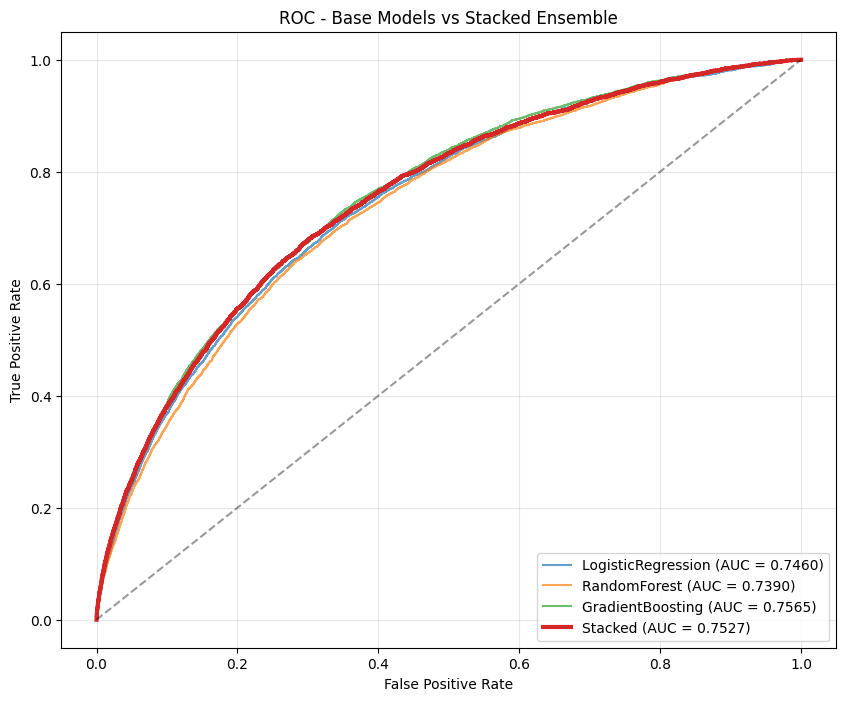

In [13]:
# ──── ROC curve comparison with bases ────────────────────────────
base_probs = pd.read_csv('../notebooks/base_probabilities.csv')

plt.figure(figsize=(10,8))

for col in base_probs.columns:
    fpr, tpr, _ = roc_curve(y_test, base_probs[col])
    plt.plot(fpr, tpr, label=f'{col} (AUC = {roc_auc_score(y_test, base_probs[col]):.4f})', alpha=0.7)

fpr, tpr, _ = roc_curve(y_test, stacked_probs)
plt.plot(fpr, tpr, label=f'Stacked (AUC = {auc:.4f})', linewidth=3)

plt.plot([0,1],[0,1], 'k--', alpha=0.4)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC - Base Models vs Stacked Ensemble')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.savefig('../reports/figures/04_stacking_roc_comparison.png', dpi=150, bbox_inches='tight')
plt.show()